# Adaptive Market-Maker Strategy

Compares tuned MMM01 with the modified MMM02 across 50 paired sessions in the IBM-offset market. The saved output reports mean profit and a paired t-test. Running the first code cell starts parallel market simulations.


Running comparison experiment with the adaptive BSE engine...


100%|██████████| 50/50 [00:12<00:00,  4.04it/s]

MMM01*: 398.70
MMM02 : 552.13
Diff: 153.43


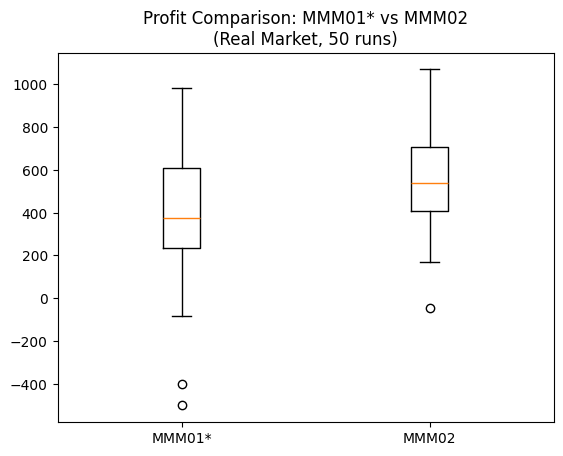

In [ ]:
import concurrent.futures
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from tqdm import tqdm
import market_maker_comparison
import importlib

importlib.reload(market_maker_comparison)

# Parameters selected by the MMM01 grid search.
best_params_q3 = {'n_past_trades': 20, 'bid_percent': 0.9, 'ask_delta': 10}
# Apply the same tuned parameters to MMM02.
mmm02_params = best_params_q3.copy()

CSV_FILE = 'data/ibm_price_offsets.csv'
SIM_DURATION = 600
N_TRIALS = 50

tasks = [(i, best_params_q3, mmm02_params, SIM_DURATION, CSV_FILE) for i in range(N_TRIALS)]

print(f"Running comparison experiment with the adaptive BSE engine...")

# Run the paired simulations.
results_01 = []
results_02 = []

if __name__ == '__main__':
    with concurrent.futures.ProcessPoolExecutor() as executor:
        results = list(tqdm(executor.map(market_maker_comparison.run_q4_session, tasks), total=N_TRIALS))

for r1, r2 in results:
    results_01.append(r1)
    results_02.append(r2)

# Summarise mean profit.
mean_01 = np.mean(results_01)
mean_02 = np.mean(results_02)

print(f"MMM01*: {mean_01:.2f}")
print(f"MMM02 : {mean_02:.2f}")
print(f"Diff: {mean_02 - mean_01:.2f}")

# Compare the profit distributions.
plt.boxplot([results_01, results_02], tick_labels=['MMM01*', 'MMM02'])
plt.title(f'Profit Comparison: MMM01* vs MMM02\n(Real Market, {N_TRIALS} runs)')
plt.show()

In [ ]:
import scipy.stats as stats

# Paired t-test.
t_stat, p_val = stats.ttest_rel(results_01, results_02)

print(f"T-statistic: {t_stat:.4f}")
print(f"P-value:     {p_val:.4e}")  

# Interpret the paired test.
if p_val < 0.05:
    print(f"\nPaired t-test p-value: {p_val:.4e}.")
    print("Reject the null hypothesis.")
    if p_val < 0.01:
        print("MMM02 achieves higher mean profit than MMM01*, with a statistically significant difference at the 1% level.")
    else:
        print("MMM02 achieves higher mean profit than MMM01*, with a statistically significant difference at the 5% level.")
else:
    print(f"\nPaired t-test p-value: {p_val:.4f}. Fail to reject the null hypothesis.")

T-statistic: -2.8277
P-value:     6.7717e-03

Paired t-test p-value: 6.7717e-03.
Reject the null hypothesis.
MMM02 achieves higher mean profit than MMM01*, with a statistically significant difference at the 1% level.
